In [17]:
import os, glob
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from tqdm import tqdm

plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300


In [18]:
data_dir = r"D:\!Work\IFA\!data\Urban_fluxes_NE\processed"

cities2test = ['Moscow', 'Tomsk']
corr_str = {'Tomsk':'3dcorr'}

dfs = {}

for city in cities2test:
    files = glob.glob(data_dir + '/' + city + (('_' + corr_str[city]) if city in corr_str else '') + '/*.csv')
    display(files)

    for file in files:
        fname = os.path.basename(file).split('.')[0]
        if 'ERA5' in fname: continue
        df = pd.read_csv(file, parse_dates=[0], index_col=[0])
        dfs[city + '_' + fname] = df

display(dfs.keys())       


['D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Moscow\\ERA5.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Moscow\\MSU_11m.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Moscow\\MSU_19m.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Moscow\\MSU_2m.csv']

['D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Tomsk_3dcorr\\BEK.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Tomsk_3dcorr\\ERA5.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Tomsk_3dcorr\\IMCES_30m.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Tomsk_3dcorr\\IMCES_40m.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Tomsk_3dcorr\\IMCES_MEZO_30m.csv',
 'D:\\!Work\\IFA\\!data\\Urban_fluxes_NE\\processed/Tomsk_3dcorr\\Oblkom.csv']

dict_keys(['Moscow_MSU_11m', 'Moscow_MSU_19m', 'Moscow_MSU_2m', 'Tomsk_BEK', 'Tomsk_IMCES_30m', 'Tomsk_IMCES_40m', 'Tomsk_IMCES_MEZO_30m', 'Tomsk_Oblkom'])

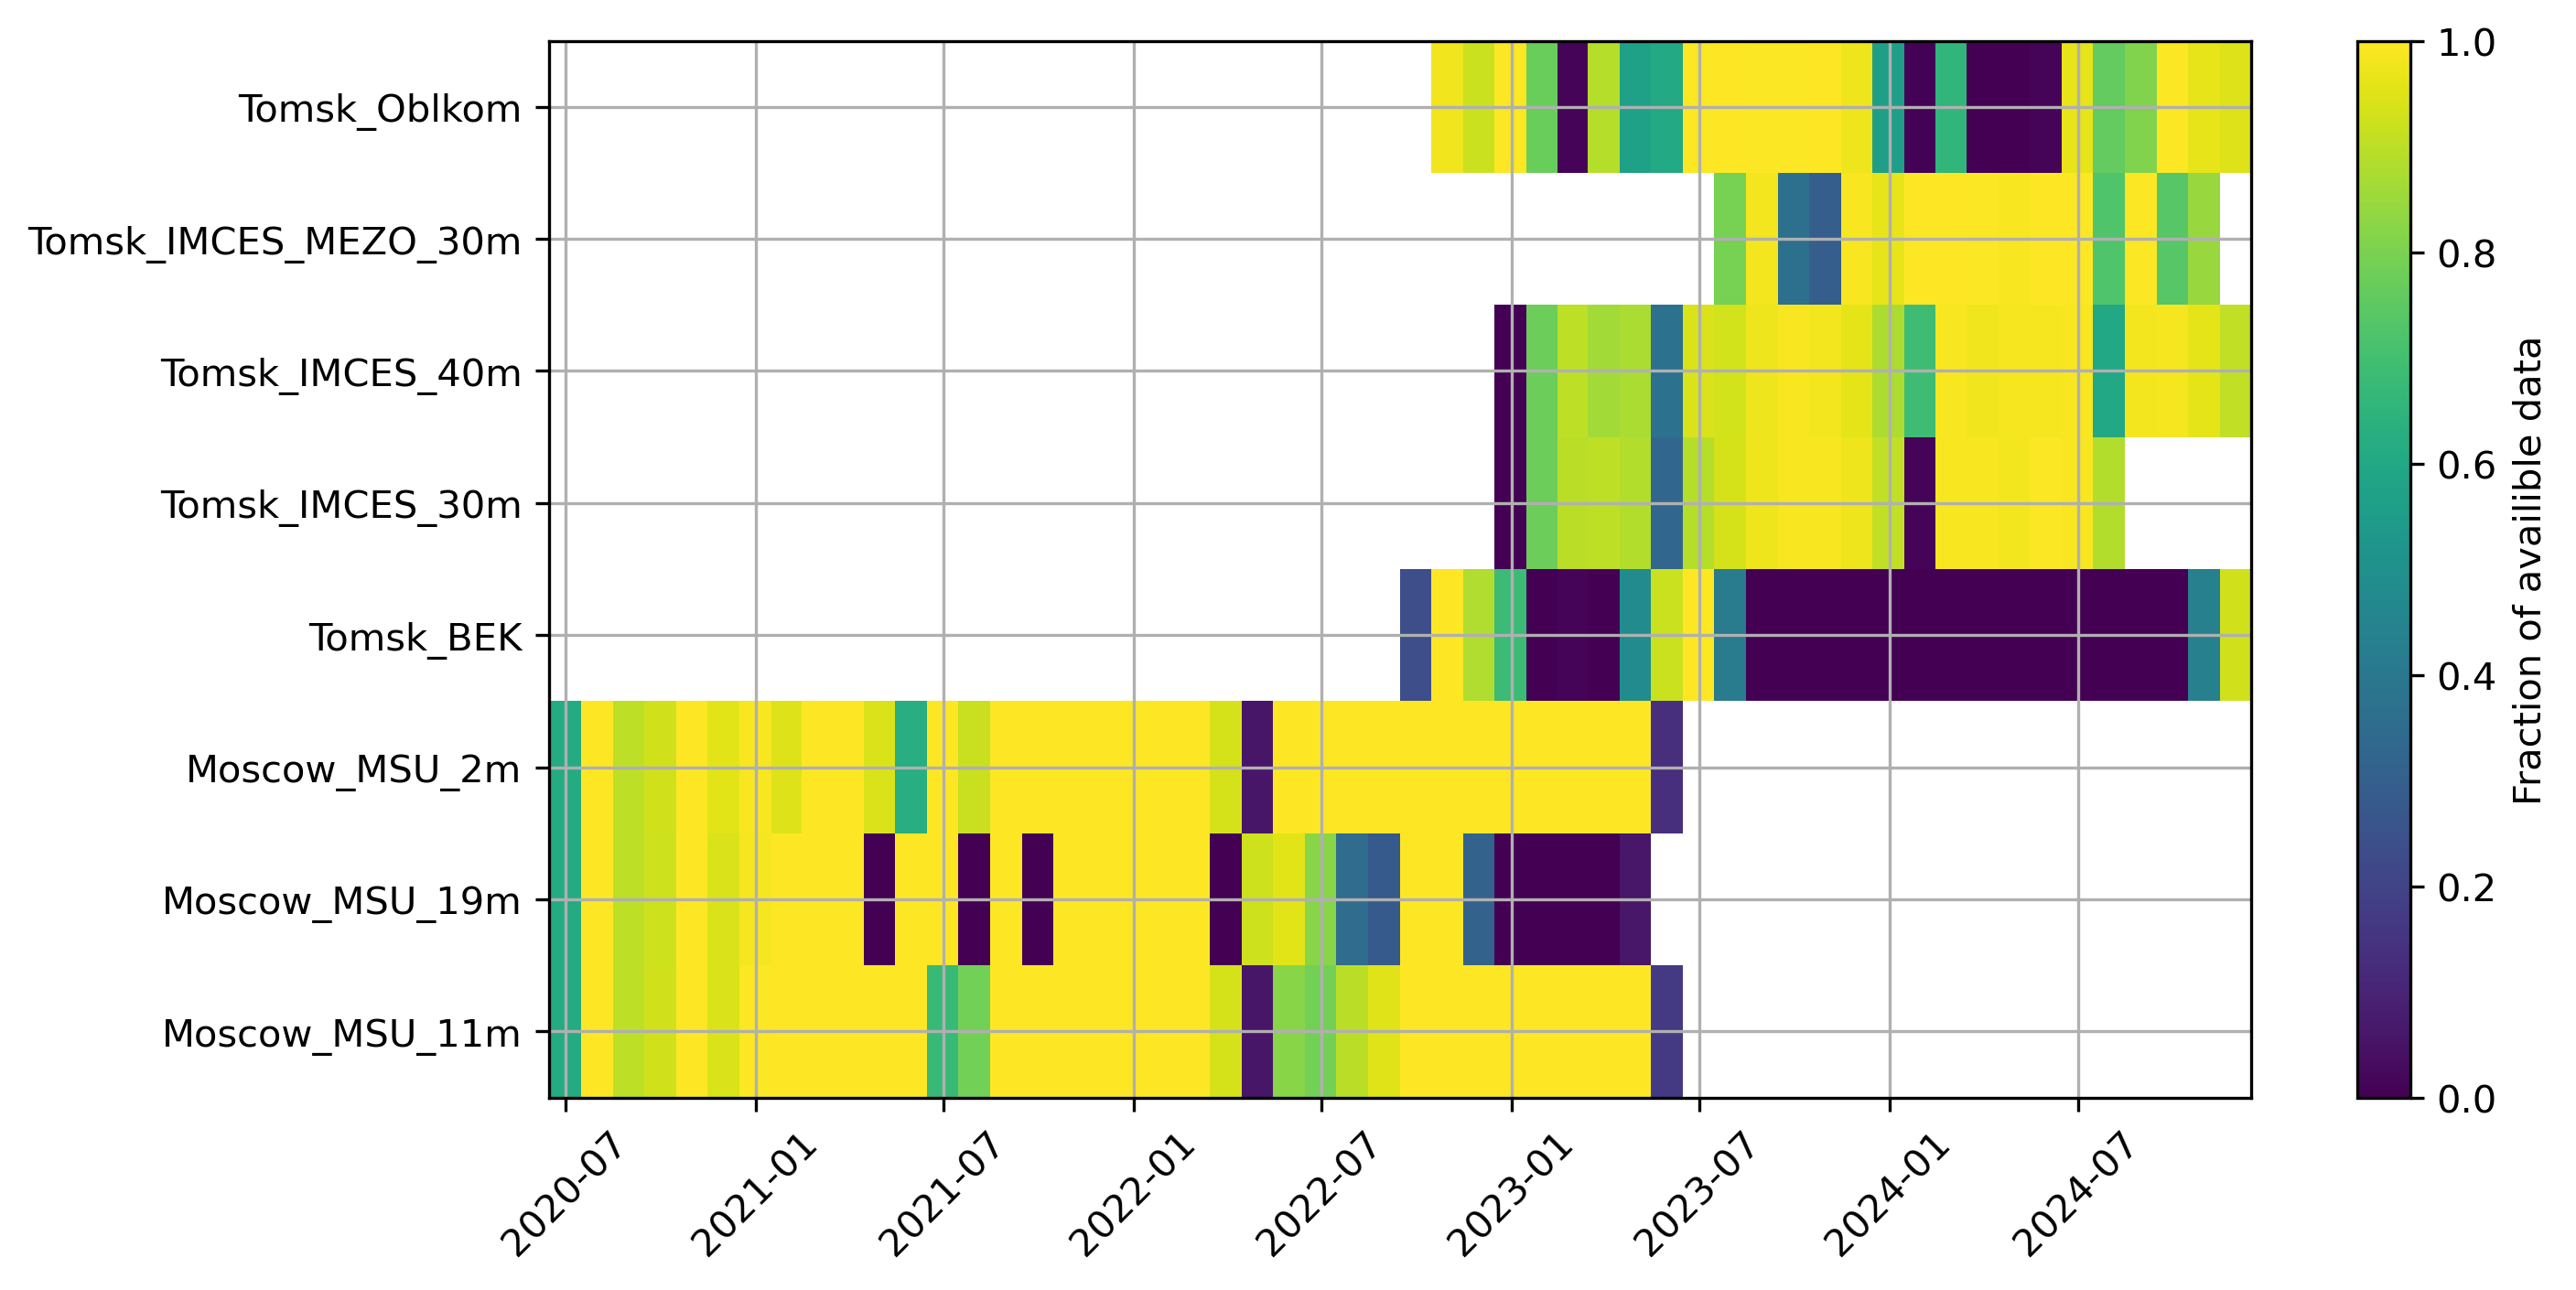

In [25]:
df_is_ok = pd.DataFrame()

for i, site in enumerate (dfs.keys()):
    df4site = dfs[site]
    
    is_ok4site = pd.DataFrame(~np.isnan(df4site['Qh'])).rename(columns = {'Qh': site})
    is_ok4site_dm = is_ok4site.astype(float).fillna(0).resample('M').mean()    
    df_is_ok = df_is_ok.merge(is_ok4site_dm, how = 'outer', right_index = True, left_index = True)

# display(df_is_ok)

# #data = df_is_ok.astype(float).fillna(0).resample('M').mean()
plt.figure(figsize=(10,5))
plt.pcolormesh(df_is_ok.index, df_is_ok.columns, df_is_ok.T.to_numpy())
plt.grid()
cb = plt.colorbar (location='right')
cb.set_label('Fraction of availible data')
_ = plt.xticks(rotation=45)
